# M3 — Feature selection on the 131 hand-crafted ECG features
Walk-through of `src/selection.py`: **filter → wrapper → embedded → metaheuristic** methods, the 1-SE parsimony rule and the nested-CV check for selection bias.

Rules: only the 80 % training part is used (test set never touched); imputation + scaling are fitted per fold on that fold's training rows; the scorer is a class-balanced logistic regression (C=1), score = mean macro-F1 over the shared 5 folds.

Cheap parts run live; expensive ones (wrappers, GA/PSO/GWO, nested CV) are controlled by `RUN_HEAVY` and otherwise read from `results/models/m3/`.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import selection as S
from src.evaluate import load_task, train_part
from src.loaders import MODELS_DIR

RUN_HEAVY = False          # True = re-run wrappers / metaheuristics / nested CV (minutes to hours)
OUT = MODELS_DIR / "m3"
X, y, splits = load_task()
Xtr, ytr = train_part(X, y, splits)
task = S.Task(Xtr, ytr, splits["folds"])
print(Xtr.shape, "classes:", ytr.nunique(), "| folds:", len(task.folds))

(5232, 131) classes: 6 | folds: 5


## 1. Building blocks
* `Task` — training rows plus per-fold preprocessed arrays `(Xa, ya, Xb, yb)`.
* `fold_scores` — macro-F1 per fold for a column subset.
* `one_se_pick` — smallest model whose mean is within one standard error of the best.
* `choose_k` — CV curve over the top-k of a ranking, k chosen by the 1-SE rule.

In [2]:
all_scores = S.fold_scores(task.fold_data, np.arange(task.p))
print("all 131 features, per-fold macro-F1:", all_scores.round(3), "mean", all_scores.mean().round(3))
# 1-SE rule on a toy curve: best is 0.81 (k=50) but k=10 is within one SE, so it is picked
print("picked index:", S.one_se_pick([0.80, 0.808, 0.81], [0.01, 0.01, 0.01], [30, 10, 50], 5))

all 131 features, per-fold macro-F1: [0.755 0.749 0.781 0.757 0.765] mean 0.762
picked index: 1


## 2. Filter methods
Rank features without training a model. Scores: ANOVA F, mutual information, chi² (min-max scaled), winsorised variance. Redundant features (|r| > 0.95) are pruned greedily, keeping the one with the higher ANOVA F.

In [3]:
sc = S.filter_scores(task)
display(sc.sort_values("anova_f", ascending=False).head(10).round(3))
res = {}
for name in ["filter_variance", "filter_corr", "filter_anova", "filter_mi", "filter_chi2"]:
    res[name] = S.METHODS[name](task)
    print(f"{name:16s} k={res[name]['k']:3d}  ({res[name]['time_s']:.1f}s)")

,anova_f,mutual_info,chi2,var_minmax
V1_skew,1194.952,0.366,97.678,0.074
pnn50,1164.509,0.383,1077.422,0.099
rr_irregularity,1019.475,0.373,373.030,0.052
rr_cv,1011.777,0.362,353.028,0.061
rr_min,831.394,0.337,208.637,0.057
rmssd,585.759,0.323,198.249,0.045
rr_median,538.532,0.263,101.864,0.045
V1_r_amp,532.516,0.222,63.153,0.044
rr_std,518.382,0.314,186.108,0.049
p_detected_frac,495.731,0.212,70.513,0.045


filter_variance  k=130  (2.5s)


filter_corr      k=125  (2.6s)


filter_anova     k= 65  (5.9s)


filter_mi        k= 80  (4.7s)


filter_chi2      k= 65  (4.7s)


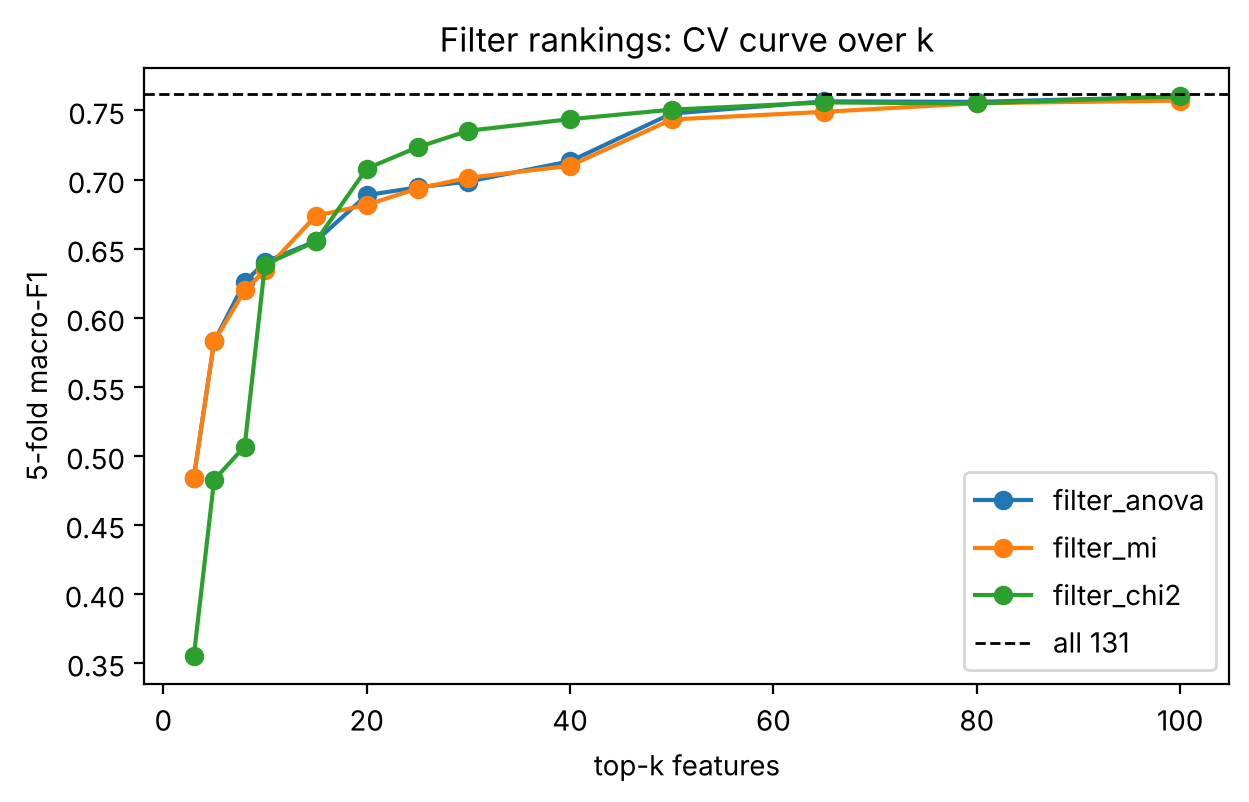

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for n in ["filter_anova", "filter_mi", "filter_chi2"]:
    c = res[n]["meta"]["curve"]; ax.plot(c["k"], c["cv_f1"], marker="o", label=n)
ax.axhline(all_scores.mean(), color="k", ls="--", lw=1, label="all 131")
ax.set(xlabel="top-k features", ylabel="5-fold macro-F1", title="Filter rankings: CV curve over k"); ax.legend(); plt.show()

## 3. Wrapper methods
Greedy search that scores subsets with the actual model: forward selection (SFS), backward elimination (SBS, from the correlation-pruned set), and RFECV. Early stopping after `patience` steps without gain. SFS took ~10 min, so by default the saved result is loaded.

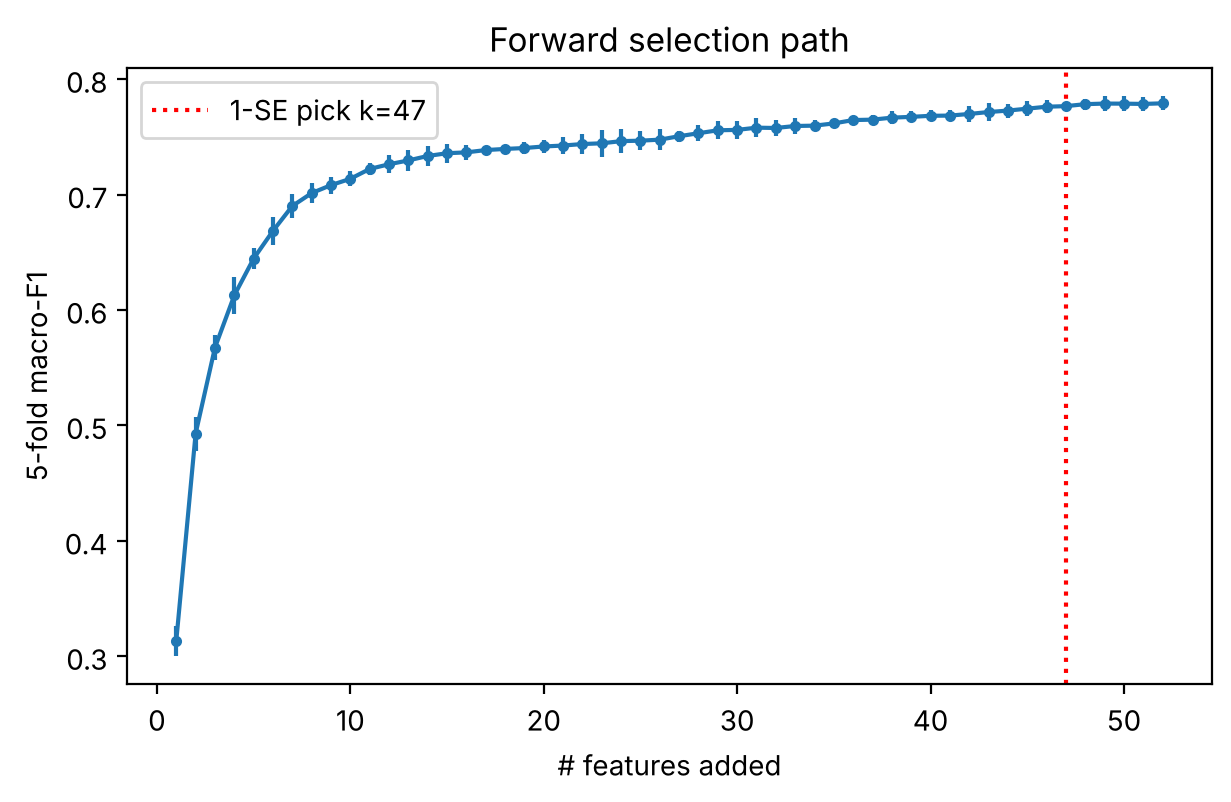

best path score: 0.779 at k = 52 | picked k = 47


In [5]:
def load(name):
    f = OUT / "subsets" / f"{name}.json"
    return json.loads(f.read_text()) if f.exists() else None

sfs = S.select_sfs(task, max_k=60) if RUN_HEAVY else load("wrapper_sfs")
if sfs:
    st = pd.DataFrame(sfs["meta"]["steps"])
    fig, ax = plt.subplots(figsize=(7, 4)); ax.errorbar(st.k, st.cv_f1, st.cv_std, marker=".")
    ax.axvline(sfs["k"], color="r", ls=":", label=f"1-SE pick k={sfs['k']}")
    ax.set(xlabel="# features added", ylabel="5-fold macro-F1", title="Forward selection path"); ax.legend(); plt.show()
    print("best path score:", st.cv_f1.max().round(4), "at k =", int(st.k[st.cv_f1.idxmax()]), "| picked k =", sfs["k"])
else:
    print("no saved SFS result; set RUN_HEAVY = True")

In [6]:
if RUN_HEAVY:
    for n in ["wrapper_sbs", "wrapper_rfecv_logreg", "wrapper_rfecv_lgbm"]:
        res[n] = S.METHODS[n](task); print(n, res[n]["k"])

## 4. Embedded methods
Selection happens inside the model: L1 (Lasso), Elastic Net (l1_ratio 0.25/0.5/0.75), L2 (rank by |coef|, cut by CV curve) and random-forest importance. Needs scikit-learn ≥ 1.8 so `l1_ratio` is honoured. These are fast, so they run live.

In [7]:
path = S.regularisation_path(task, 1.0)
display(path[["C", "cv_f1", "cv_std", "n_nonzero"]].round(3))
for n in ["embedded_l1", "embedded_elasticnet", "embedded_l2", "embedded_rf"]:
    res[n] = S.METHODS[n](task); print(f"{n:22s} k={res[n]['k']:3d} ({res[n]['time_s']:.0f}s)")

,C,cv_f1,cv_std,n_nonzero
0,0.001,0.048,0.024,5
1,0.002,0.579,0.019,15
2,0.006,0.679,0.007,36
3,0.013,0.720,0.005,69
4,0.032,0.744,0.013,99
5,0.075,0.752,0.011,119
6,0.178,0.757,0.012,127
7,0.422,0.757,0.017,131
8,1.000,0.757,0.016,131


embedded_l1            k=119 (73s)


embedded_elasticnet    k=122 (212s)


embedded_l2            k= 40 (42s)


embedded_rf            k= 65 (5s)


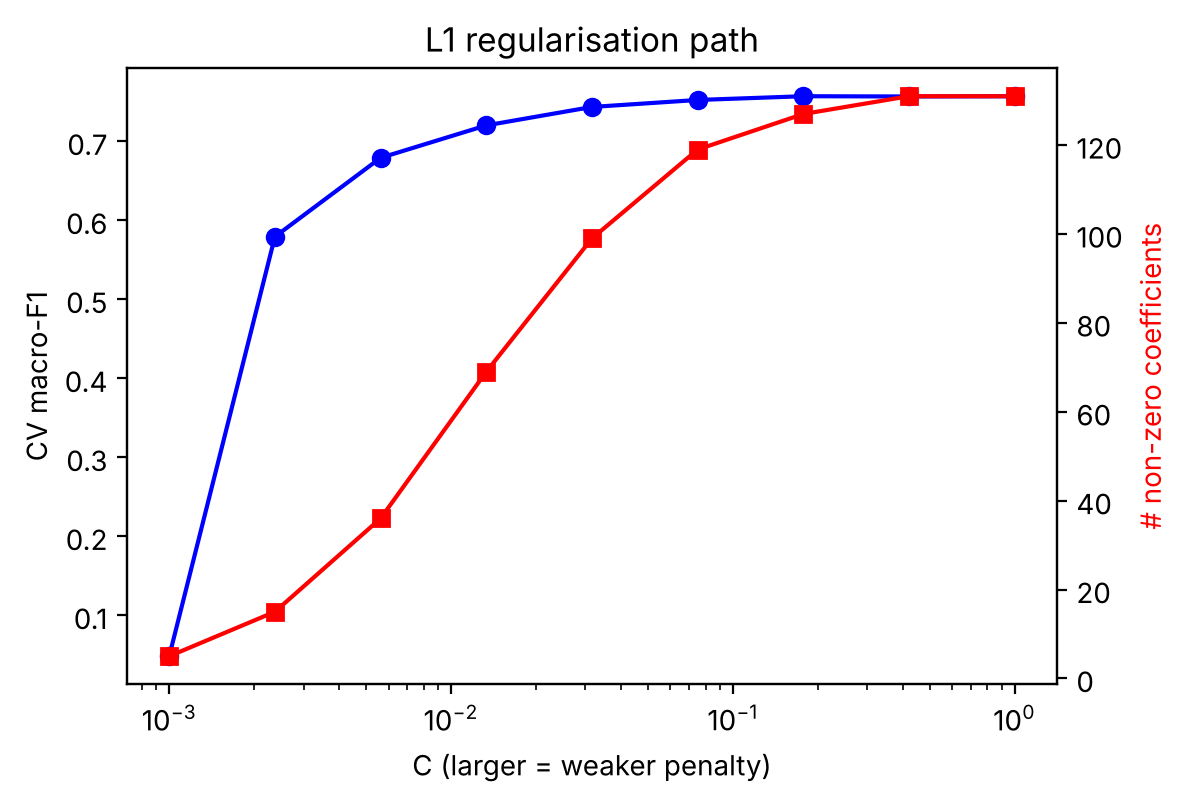

In [8]:
fig, ax = plt.subplots(figsize=(6, 4)); ax2 = ax.twinx()
ax.plot(path.C, path.cv_f1, "b-o"); ax2.plot(path.C, path.n_nonzero, "r-s")
ax.set(xscale="log", xlabel="C (larger = weaker penalty)", ylabel="CV macro-F1"); ax2.set_ylabel("# non-zero coefficients", color="r")
ax.set_title("L1 regularisation path"); plt.show()

## 5. Metaheuristics (GA, binary PSO, binary GWO)
Global search over bit-masks of length 131. Fitness = CV macro-F1 − 0.05·k/131 (penalises size). A cached parallel evaluator avoids re-scoring identical masks; early stopping after `patience` stale generations.
* **GA** (DEAP): tournament (3), two-point crossover, bit-flip mutation, elitism.
* **PSO**: velocity update, inertia 0.9→0.4, bit set with prob. sigmoid(v).
* **GWO**: alpha/beta/delta leaders; simplified variant of Emary et al. (leader proposals averaged, no crossover step).

Below, a tiny budget shows the mechanics; the real runs use pop≈40, 40 generations.

GA: k=31  cv_f1=0.715  generations=5  evals=51  (6s)


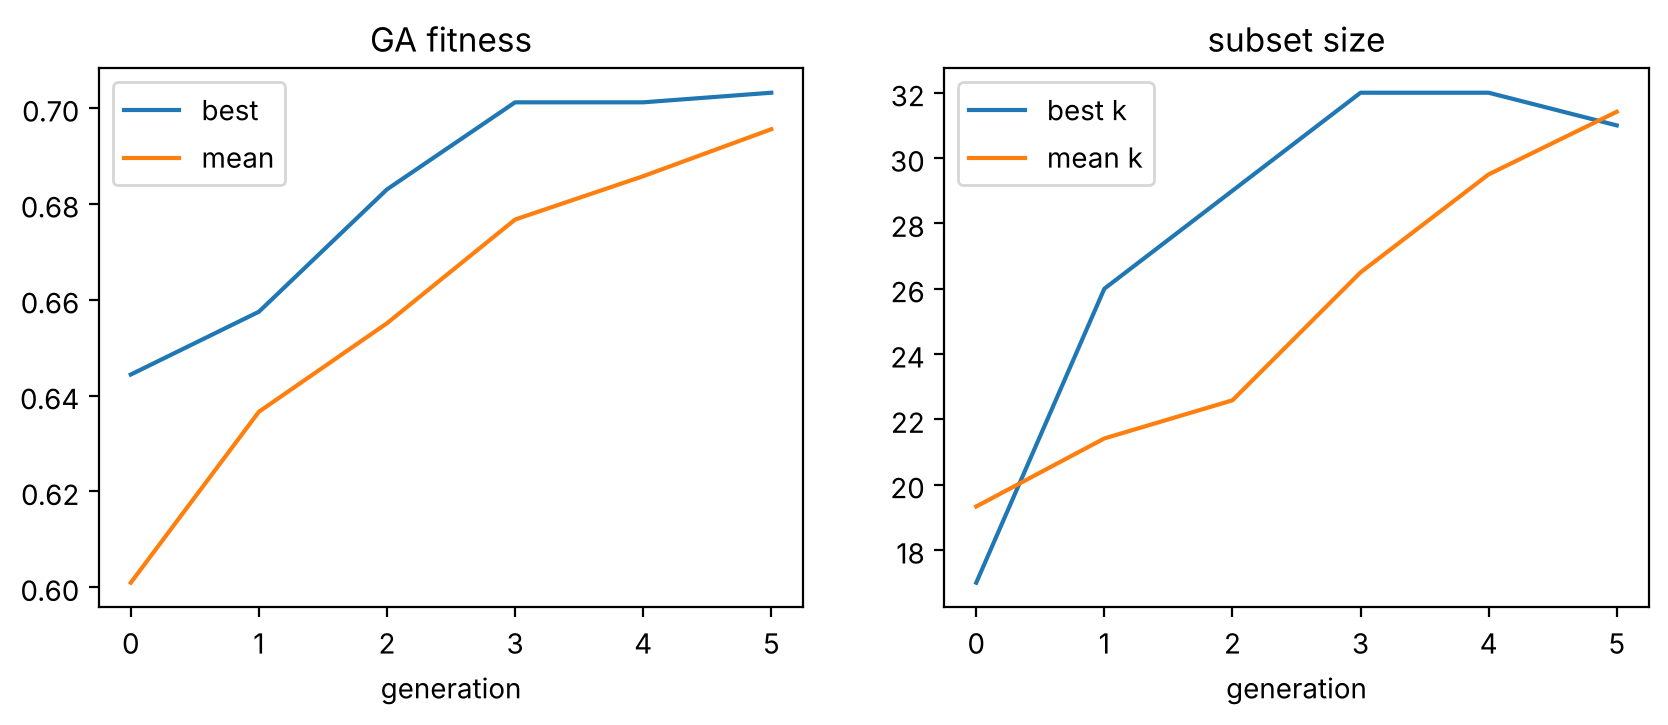

In [9]:
kw = dict(pop=40, ngen=40) if RUN_HEAVY else dict(pop=12, ngen=5)
t = time.time(); ga = S.select_ga(task, **kw)
print(f"GA: k={ga['k']}  cv_f1={ga['meta']['cv_f1']:.3f}  generations={ga['meta']['stopped_gen']}  evals={ga['meta']['n_evals']}  ({time.time()-t:.0f}s)")
h = pd.DataFrame(ga["meta"]["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.gen, h.best_fitness, label="best"); ax[0].plot(h.gen, h.mean_fitness, label="mean"); ax[0].set(xlabel="generation", title="GA fitness"); ax[0].legend()
ax[1].plot(h.gen, h.best_k, label="best k"); ax[1].plot(h.gen, h.mean_k, label="mean k"); ax[1].set(xlabel="generation", title="subset size"); ax[1].legend(); plt.show()

In [10]:
if RUN_HEAVY:
    for n in ["meta_pso", "meta_gwo"]:
        res[n] = S.METHODS[n](task, log=print); print(n, res[n]["k"])

## 6. Nested CV — measuring selection bias
The CV score that guided a search is optimistic. `nested_score` repeats the *entire* selection inside each outer training fold (3 inner folds), refits logistic regression on the chosen features and scores the untouched outer validation rows. The nested F1 is the honest number for comparing methods.

In [11]:
nested = {}
for name in ["filter_anova"] + (list(S.METHODS) if RUN_HEAVY else []):
    f = OUT / "nested" / f"{name}.csv"
    nested[name] = pd.read_csv(f) if f.exists() else S.nested_score(name, Xtr, ytr, task.folds, log=lambda *a: None)
for n, d in nested.items():
    print(f"{n:16s} nested macro-F1 {d.f1_macro.mean():.3f} ± {d.f1_macro.std(ddof=1):.3f}   mean k {d.k.mean():.0f}")

filter_anova     nested macro-F1 0.758 ± 0.014   mean k 71


## 7. Comparing and overlapping subsets
Jaccard overlap between selected subsets and a vote count (how many discriminative selectors keep each feature).

In [12]:
subs = {n: r for n, r in res.items()}
if sfs: subs["wrapper_sfs"] = sfs
names = list(subs)
J = pd.DataFrame([[S.jaccard(subs[a]["features"], subs[b]["features"]) for b in names] for a in names], index=names, columns=names)
display(J.round(2))
sel = [n for n in names if n not in ("filter_variance", "filter_corr")]
votes = pd.Series({f: sum(f in subs[n]["features"] for n in sel) for f in X.columns}).sort_values(ascending=False)
print(f"features kept by all {len(sel)} discriminative selectors:", int((votes == len(sel)).sum()))
votes.head(15)

,filter_variance,filter_corr,filter_anova,filter_mi,filter_chi2,embedded_l1,embedded_elasticnet,embedded_l2,embedded_rf,wrapper_sfs
filter_variance,1.00,0.95,0.50,0.60,0.49,0.92,0.94,0.31,0.49,0.35
filter_corr,0.95,1.00,0.52,0.64,0.52,0.88,0.90,0.29,0.47,0.33
filter_anova,0.50,0.52,1.00,0.75,0.57,0.52,0.53,0.40,0.59,0.30
filter_mi,0.60,0.64,0.75,1.00,0.56,0.62,0.62,0.36,0.67,0.37
filter_chi2,0.49,0.52,0.57,0.56,1.00,0.50,0.51,0.35,0.44,0.37
embedded_l1,0.92,0.88,0.52,0.62,0.50,1.00,0.98,0.34,0.53,0.35
embedded_elasticnet,0.94,0.90,0.53,0.62,0.51,0.98,1.00,0.33,0.52,0.35
embedded_l2,0.31,0.29,0.40,0.36,0.35,0.34,0.33,1.00,0.50,0.40
embedded_rf,0.49,0.47,0.59,0.67,0.44,0.53,0.52,0.50,1.00,0.40
wrapper_sfs,0.35,0.33,0.30,0.37,0.37,0.35,0.35,0.40,0.40,1.00


features kept by all 8 discriminative selectors: 18


rr_median          8
rr_max             8
rr_min             8
age                8
qrs_duration       8
rr_cv              8
rmssd              8
rr_irregularity    8
pnn50              8
rr_short_frac      8
pr_interval        8
p_detected_frac    8
V2_s_amp           8
p_duration         8
V1_r_amp           8
dtype: int64

## 8. Final choice and how to reproduce the full run
`choose_final` (in `scripts/make_m3_outputs.py`) takes the method with the best nested F1, then the one with the fewest features among those within 1 SE of it, and writes `selected_features.json`. That score is selection-adjusted (slightly optimistic).

```bash
python scripts/run_m3_selection.py select      # subsets/<method>.json
python scripts/run_m3_selection.py nested      # nested/<method>.csv
python scripts/run_m3_selection.py classify    # subsets_cv.csv (logreg / SVM / LightGBM)
python scripts/make_m3_outputs.py              # figures 30-38 + selected_features.json
```